# Session 6 — Artificial Neural Networks
**Sebastián Ríos · Computer Vision & Speech Recognition · EADA**

Class notebook, adapted to run in my own `Milk10k-project` repo. I commented the code and the outputs, and did the exercises at the end (mini challenge + homework before Session 7).

**What I changed so it runs on my machine**
- The class code imports `common.config` and `common.milk10k`, which aren't in my repo. My equivalents are `milk10k_pipeline.config` (paths, image folder) and the leak-free lesion-level splits I saved in Milestone 1 (`outputs/splits/{train,val,test}.csv`, seed 42).
- Everything this notebook writes goes to `outputs/session_06/`, inside the repo.
- The class compares against Session 5's random forest stored in `session_05_classical_ml/_output/baseline_scores.json`. I don't have that file, so I retrain that baseline (random forest on the same 33 features, same split) inside this notebook. That keeps the comparison fair.
- Because my split is different from the professor's (3,742 / 749 / 749 lesions rather than 3,593 / 599 / 1,048), the MILK10k numbers in sections 7–11 differ from the ones in the class comments. I replaced those comments with my own results.

#### 0. Setup

In [1]:
import sys
import time
import json
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repo root by walking up from the current folder until we see milk10k_pipeline/config.py
# (the class version looked for common/config.py, which my repo doesn't have).
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "milk10k_pipeline" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

from milk10k_pipeline import config     # data only: DATA_DIR, IMAGE_DIR, image_path(), SPLIT_DIR

OUT = config.OUTPUT_DIR / "session_06"  # everything this notebook writes goes here
OUT.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no scientific notation
print(ROOT)
print(config.describe())

C:\Users\Dell\OneDrive\Desktop\EADA\4th Year\Computer Vision & Speech Recognition\Milk10k-project
DATA_DIR=C:\Users\Dell\OneDrive\Desktop\EADA\4th Year\Computer Vision & Speech Recognition\milk10k_project | IMAGE_DIR=C:\Users\Dell\OneDrive\Desktop\EADA\4th Year\Computer Vision & Speech Recognition\milk10k_project\images | SEED=42 | IMG_SIZE=224


**Output.** The repo root resolves to my `Milk10k-project` folder, and `config` reads the data from `milk10k_project` (the folder next to the repo), so this replaces the class's `common/` setup. `IMG_SIZE=224` comes from my Milestone 1 config. This notebook doesn't use it, because section 7 resizes to 200×150 and homework 3 to 32×32.

### 1. One neuron, by hand → in NumPy

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))   # squashes any real number into (0, 1) -> reads as a probability

def neuron(x, w, b):
    z = np.dot(x, w) + b          # 1. weighted sum: z = w1*x1 + w2*x2 + b
    return z, sigmoid(z)          # 2. activation: turn the score into a probability

x = np.array([0.6, 0.2])          # one lesion, two features: edge density, color asymmetry (normalized 0-1)
w = np.array([1.5, -0.5])         # weights: edge density pushes towards "malignant", asymmetry slightly against
b = -0.4                          # bias: shifts the threshold
neuron(x, w, b)                   # by hand: z = 1.5*0.6 - 0.5*0.2 - 0.4 = 0.4 ; sigmoid(0.4) = 0.599

(np.float64(0.3999999999999999), np.float64(0.598687660112452))

**Output.** `z = 0.4` and `y_hat = 0.599`, the same as the hand calculation: 1.5·0.6 − 0.5·0.2 − 0.4 = 0.4, and σ(0.4) ≈ 0.599. A single neuron is just a weighted sum followed by a squashing function. With a sigmoid it is exactly logistic regression. The (numerical) 0.39999… is floating-point rounding, not a bug.

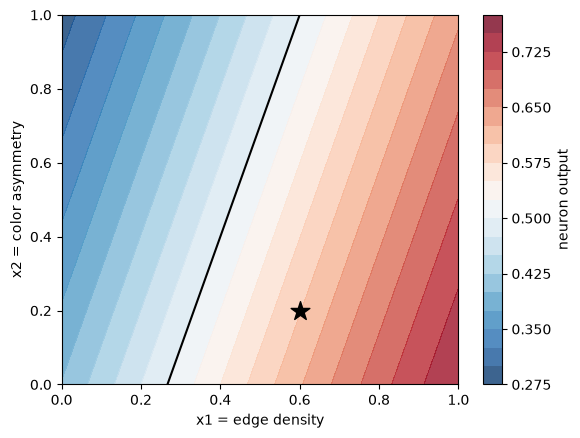

In [3]:
# Evaluate the same neuron on a 200x200 grid of (x1, x2) values to see its whole "map" of outputs.
g1, g2 = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
_, p = neuron(np.stack([g1, g2], axis=-1), w, b)       # np.dot over the last axis -> works on the whole grid at once

plt.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.8)   # colour = neuron output (blue ~0, red ~1)
plt.colorbar(label="neuron output")
plt.contour(g1, g2, p, levels=[0.5], colors="k")       # the decision boundary: output 0.5 <=> z = 0 (a straight line)
plt.scatter(*x, c="k", marker="*", s=200)              # our lesion: 0.599, just on the "malignant" side
plt.xlabel("x1 = edge density"); plt.ylabel("x2 = color asymmetry");

**Plot.** The output changes smoothly from blue (≈0) to red (≈1). The black 0.5 contour, which is the decision boundary, is a **straight line**: it is where z = 1.5·x1 − 0.5·x2 − 0.4 = 0. Whatever the weights, one neuron can only cut the plane with a line. They only change where the line sits and how sharp the transition is. Our lesion (★) sits just on the red side (0.599).

### 2. XOR — what one line cannot do

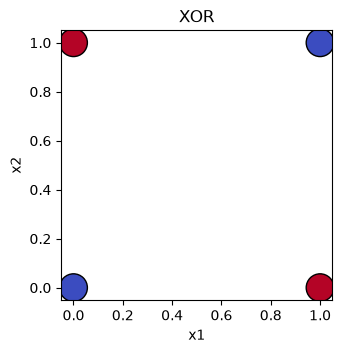

In [4]:
# XOR: output 1 only when exactly one input is 1. The two classes sit on opposite corners.
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

plt.figure(figsize=(3.5, 3.5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("XOR");

**Plot.** The two red points (class 1) are on one diagonal and the two blue points (class 0) on the other. No single straight line can put both reds on one side and both blues on the other, so one neuron (or logistic regression) **cannot** learn XOR.

In [5]:
def relu(z):
    return np.maximum(0, z)              # ReLU: keep positives, set negatives to 0 (the non-linearity)

# Hand-picked weights for a 2-2-1 network that solves XOR
W1 = np.array([[1, 1],
               [1, 1]], dtype=float)     # column j = weights of hidden neuron j -> both compute x1 + x2
b1 = np.array([0, -1], dtype=float)      # h1 = relu(x1 + x2),  h2 = relu(x1 + x2 - 1)  (h2 fires only for (1,1))
W2 = np.array([1, -2], dtype=float)      # output = h1 - 2*h2 -> subtracts the (1,1) case back to 0

H = relu(X_xor @ W1 + b1)                # hidden layer: 4 inputs x 2 neurons (matrix product does all 4 at once)
out = H @ W2
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1],
              "h1": H[:, 0], "h2": H[:, 1], "output": out, "XOR": y_xor})

,x1,x2,h1,h2,output,XOR
0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,1.0,1.0,0.0,1.0,1
2,1.0,0.0,1.0,0.0,1.0,1
3,1.0,1.0,2.0,1.0,0.0,0


**Output.** The `output` column matches `XOR` exactly. h1 = x1 + x2 counts how many inputs are on. h2 only fires when both are on, which is (1,1) → 1. The output h1 − 2·h2 then subtracts that case: 2 − 2 = 0. So two hidden neurons plus a ReLU solve what one neuron can't.

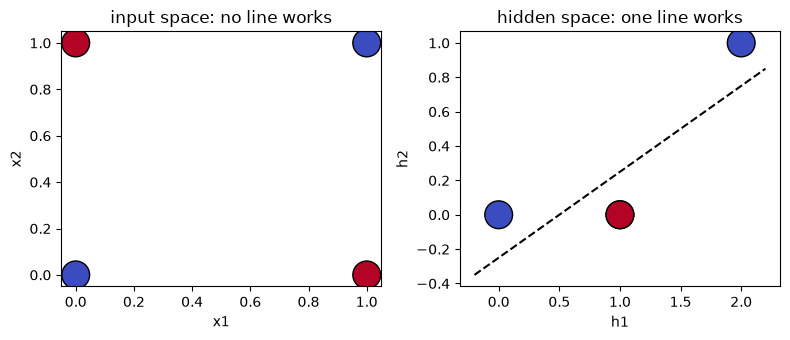

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
# Left: original inputs. Right: the same 4 points after the hidden layer (h1, h2).
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
axes[0].set_title("input space: no line works"); axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
h1_line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(h1_line, (h1_line - 0.5) / 2, "k--")       # output = h1 - 2*h2 = 0.5  ->  h2 = (h1 - 0.5) / 2
axes[1].set_title("hidden space: one line works"); axes[1].set_xlabel("h1"); axes[1].set_ylabel("h2")
plt.tight_layout()

**Plot.** On the left (input space) no line works. On the right are the same 4 points in hidden space (h1, h2): (0,0) → (0,0), the two class-1 points both land on (1,0), and (1,1) → (2,1). Now one dashed line separates them. **This is the key idea of a hidden layer: it moves the data into a new space where a simple linear rule is enough.** A CNN does the same thing, only with many more layers and learned features.

In [7]:
# What happens WITHOUT the ReLU? Two linear layers in a row...
linear_out = (X_xor @ W1 + b1) @ W2               # same network, NO ReLU
collapsed = X_xor @ (W1 @ W2) + (b1 @ W2)          # ...are exactly ONE linear layer with W = W1 @ W2, b = b1 @ W2
print(linear_out, collapsed)                       # identical, and not XOR
print(W1 @ W2, b1 @ W2)                            # the single equivalent layer: weights [-1, -1], bias 2

[2. 1. 1. 0.] [2. 1. 1. 0.]
[-1. -1.] 2.0


**Output.** Without the ReLU we get `[2, 1, 1, 0]`, which is not XOR. That's exactly what the single collapsed layer gives, with W = W1·W2 = [−1, −1] and b = 2. Stacking linear layers without an activation is pointless, because the product of linear maps is just another linear map. **The non-linearity is what gives depth its power.**

### 3. Forward pass, softmax, cross-entropy

In [8]:
def forward(x, W1, b1, W2, b2):
    z_h = x @ W1 + b1          # hidden pre-activations (weighted sums)
    h = relu(z_h)              # hidden activations
    z_o = h @ W2 + b2          # output pre-activation
    return sigmoid(z_o), h, z_h   # probability of "malignant" + intermediate values (needed later for backprop)

# A 2-2-1 network with small arbitrary weights (as at initialisation)
W1 = np.array([[0.5, -0.3],
               [0.3,  0.4]]); b1 = np.array([0.1, -0.3])
W2 = np.array([0.4, -0.2]);   b2 = 0.1

y_hat, h, z_h = forward(np.array([0.6, 0.2]), W1, b1, W2, b2)
print(z_h, h, y_hat)

[ 0.46 -0.4 ] [0.46 0.  ] 0.5705266031962988


**Output.** Hidden pre-activations `z_h = [0.46, −0.40]`. After the ReLU we get `h = [0.46, 0]`: the second neuron is "off" for this input because its pre-activation is negative. Output: σ(0.4·0.46 − 0.2·0 + 0.1) = σ(0.284) = **0.571**. That's a weak "malignant" guess, which is normal for untrained weights. We keep `h` and `z_h` because backprop needs them.

In [9]:
def softmax(z):
    e = np.exp(z - z.max())    # subtract the max first: same result (it cancels out), but no overflow for big logits
    return e / e.sum()         # normalise -> positive numbers that sum to 1

logits = np.array([1.0, 2.0, 0.5])          # raw scores for Benign, Malignant, Indeterminate
print(np.exp(logits))                       # step 1: exponentiate (makes everything positive, exaggerates gaps)
print(softmax(logits))                      # step 2: divide by the sum -> probabilities

[2.718 7.389 1.649]
[0.231 0.629 0.14 ]


**Output.** The exponentials are e¹ = 2.718, e² = 7.389, e^0.5 = 1.649 (sum 11.756). Dividing by the sum gives probabilities **[0.231, 0.629, 0.140]**, which add up to 1. The largest logit (Malignant, 2.0) gets most of the mass. A gap of 1 in logits becomes a ×2.7 ratio in probability (0.629 / 0.231 ≈ e¹), so softmax exaggerates differences. Subtracting the max doesn't change the result because the constant cancels between numerator and denominator.

In [10]:
def cross_entropy(y_true_onehot, probs, eps=1e-9):
    probs = np.clip(probs, eps, 1 - eps)                 # avoid log(0) = -inf
    return -np.sum(y_true_onehot * np.log(probs))        # with one-hot truth this is just -log(p of the true class)

y_true = np.array([0, 1, 0])                             # truth: Malignant (middle class)
for probs in ([0.10, 0.70, 0.20],                        # right, fairly confident
              [0.005, 0.99, 0.005],                      # right, very confident
              [0.80, 0.10, 0.10]):                       # wrong, confident
    print(probs, "->", round(cross_entropy(y_true, np.array(probs)), 3))

[0.1, 0.7, 0.2] -> 0.357
[0.005, 0.99, 0.005] -> 0.01
[0.8, 0.1, 0.1] -> 2.303


**Output.** The loss is just −log(probability given to the true class):
- 0.70 on the true class → **0.357**: right, so a small loss.
- 0.99 → **0.010**: right and very confident, almost no loss.
- 0.10 → **2.303**: confidently wrong, a big loss.

The probabilities on the wrong classes don't enter the formula directly. They only matter because they take mass away from the true class.

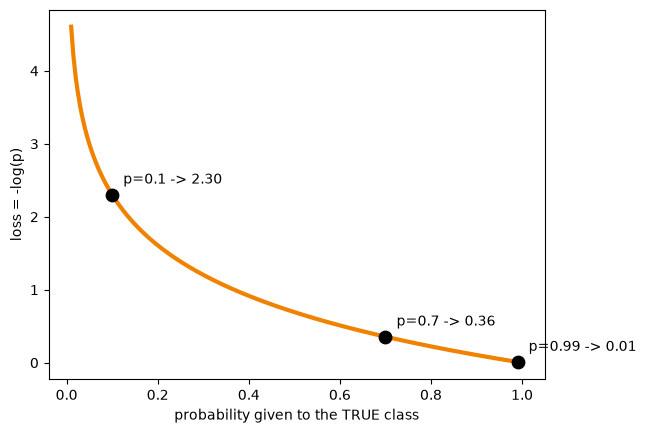

In [11]:
# The loss curve: -log(p) as a function of the probability given to the true class
p = np.linspace(0.01, 1, 200)
plt.plot(p, -np.log(p), color="#F08200", lw=3)
for q in (0.10, 0.70, 0.99):
    plt.scatter(q, -np.log(q), s=80, color="k", zorder=3)
    plt.annotate(f"p={q} -> {-np.log(q):.2f}", (q, -np.log(q)), xytext=(8, 8), textcoords="offset points")
plt.xlabel("probability given to the TRUE class"); plt.ylabel("loss = -log(p)");

**Plot.** −log(p) is close to 0 near p = 1 and shoots up as p → 0. Going from 0.99 to 0.70 costs only 0.35, but going from 0.70 to 0.10 costs about 1.95 more. Cross-entropy therefore punishes **confident mistakes** far more than hesitant ones, which is why it gives strong gradients exactly where the model is most wrong. (This is also why the `eps` clip is needed: log(0) = −∞.)

### 4. Gradient descent by hand

In [12]:
# Toy loss with one weight: L(w) = (w - 3)^2 -> minimum at w = 3
def descend(lr, w=0.0, steps=15):
    path = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)       # derivative of (w - 3)**2 = slope at the current w
        w = w - lr * grad        # one step downhill: move against the slope, scaled by the learning rate
        path.append(w)
    return np.array(path)

path = descend(lr=0.1)
print(path[:4])                  # first steps: each one covers 20% of the remaining distance to 3
print(path[-1])                  # after 15 steps -> close to 3

[0.    0.6   1.08  1.464]
2.894446883733504


**Output.** The path is 0 → 0.6 → 1.08 → 1.464 → … → **2.894** after 15 steps. With lr = 0.1 each step is w ← w − 0.2·(w − 3), so the distance to 3 shrinks by 20% per step: 3·0.8¹⁵ ≈ 0.106 left, and 3 − 0.106 = 2.894. Steps get smaller near the minimum because the slope gets smaller there. That happens on its own, without changing the learning rate.

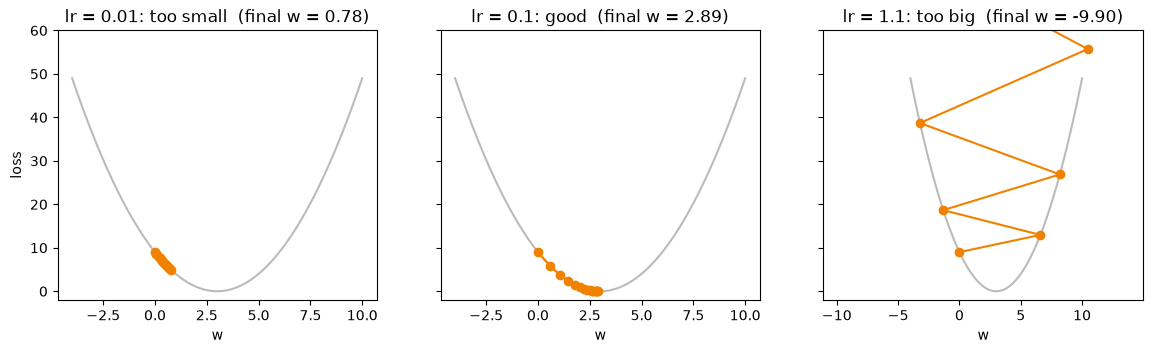

In [13]:
# Same descent with three learning rates
ws = np.linspace(-4, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, lr, title in zip(axes, [0.01, 0.1, 1.1], ["too small", "good", "too big"]):
    path = descend(lr, steps=8 if lr > 1 else 15)
    ax.plot(ws, (ws - 3) ** 2, color="#BBBBBB")                   # the loss curve
    ax.plot(path, (path - 3) ** 2, "o-", color="#F08200")         # where gradient descent went
    ax.set_title(f"lr = {lr}: {title}  (final w = {path[-1]:.2f})")
    ax.set_ylim(-2, 60); ax.set_xlabel("w")
axes[0].set_ylabel("loss");

**Plot.** The same loss with three learning rates:
- **lr = 0.01**: too small. After 15 steps it is still far from 3 (final w ≈ 0.78). It would get there, but slowly.
- **lr = 0.1**: good. It approaches 3 smoothly.
- **lr = 1.1**: too big. Each step overshoots: the factor is (1 − 2.2) = −1.2, so the distance grows ×1.2 per step and w bounces from side to side, **diverging**.

The learning rate is the most important hyper-parameter, and the mini challenge in section 11 shows the same three behaviours on a real network.

### 5. Backpropagation by hand — then let PyTorch check us

In [14]:
# Back to the single neuron of section 1 (x, w, b). The lesion is malignant -> target y = 1.
y = 1.0
z, y_hat = neuron(x, w, b)
loss = -np.log(y_hat)                         # binary cross-entropy when y = 1
print(f"forward : z={z:.3f}  y_hat={y_hat:.3f}  loss={loss:.3f}")

dz = y_hat - y                                # dLoss/dz for sigmoid + cross-entropy simplifies to (prediction - truth)
grad_w = dz * x                               # chain rule: dLoss/dw = dLoss/dz * dz/dw = dz * x
grad_b = dz * 1                               # dz/db = 1
print(f"backward: dz={dz:.3f}  grad_w={grad_w}  grad_b={grad_b:.3f}")

forward : z=0.400  y_hat=0.599  loss=0.513
backward: dz=-0.401  grad_w=[-0.241 -0.08 ]  grad_b=-0.401


**Output.**
- Forward: z = 0.4, ŷ = 0.599, loss = −log(0.599) = **0.513**.
- Backward: for sigmoid + cross-entropy, ∂L/∂z = ŷ − y = 0.599 − 1 = **−0.401**. The chain rule then gives ∂L/∂w = dz·x = −0.401·[0.6, 0.2] = **[−0.241, −0.080]** and ∂L/∂b = **−0.401**.

The gradients are negative, so *increasing* w and b lowers the loss. The weight on x1 gets the bigger gradient because x1 (0.6) is the larger input: a weight only gets blamed in proportion to the input it multiplied.

In [15]:
# One gradient-descent update with lr = 1, then re-run the forward pass
lr = 1.0
w_new = w - lr * grad_w                       # negative gradient -> weights go UP
b_new = b - lr * grad_b
z2, y_hat2 = neuron(x, w_new, b_new)
print(w_new, round(b_new, 3))
print(f"y_hat {y_hat:.3f} -> {y_hat2:.3f}   loss {loss:.3f} -> {-np.log(y_hat2):.3f}")

[ 1.741 -0.42 ] 0.001
y_hat 0.599 -> 0.723   loss 0.513 -> 0.324


**Output.** One step with lr = 1: w goes from [1.5, −0.5] to **[1.741, −0.420]** and b from −0.4 to **0.001**. The prediction rises from 0.599 to **0.723** and the loss falls from 0.513 to **0.324**. That's training in miniature: forward, loss, gradients, step, repeat. (In practice lr = 1 would be large; it's used here so the change is visible after one step.)

In [16]:
import torch
import torch.nn as nn

# Same neuron in PyTorch: autograd should reproduce our hand-computed gradients
xt = torch.tensor([0.6, 0.2])
wt = torch.tensor([1.5, -0.5], requires_grad=True)   # track gradients for these
bt = torch.tensor(-0.4, requires_grad=True)

y_hat_t = torch.sigmoid(xt @ wt + bt)                # forward, same formula
loss_t = -torch.log(y_hat_t)
loss_t.backward()                                    # backpropagation, automatic -> fills wt.grad and bt.grad

print(y_hat_t.item(), loss_t.item())
print(wt.grad, bt.grad)

0.5986876487731934 0.5130152702331543
tensor([-0.2408, -0.0803]) tensor(-0.4013)


**Output.** PyTorch gives ŷ = 0.5987, loss = 0.5130, `wt.grad = [−0.2408, −0.0803]` and `bt.grad = −0.4013`. These are **identical** to the hand-computed values, with tiny differences only because PyTorch uses float32 and NumPy float64. `.backward()` does the chain rule for us on any network, however deep. That's why we never write gradients by hand again after this cell.

### 6. A real (tiny) network learns a curved boundary

In [17]:
from sklearn.datasets import make_moons

# Two interleaving half-moons: a toy dataset that no straight line can separate
Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xm_t = torch.tensor(Xm, dtype=torch.float32)          # PyTorch layers expect float32
ym_t = torch.tensor(ym)                               # class labels as int64 (what CrossEntropyLoss wants)

def make_net(hidden):
    torch.manual_seed(0)                              # same random initial weights every time -> fair comparison
    if hidden == 0:
        return nn.Linear(2, 2)                        # no hidden layer = (multinomial) logistic regression
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, 2))

net = make_net(8)
net

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)

**Output.** The network is 2 inputs → 8 hidden neurons (Linear + ReLU) → 2 outputs (one logit per class). That's 2·8 + 8 + 8·2 + 2 = **42 parameters**. There's no softmax at the end because `nn.CrossEntropyLoss` applies it internally.

In [18]:
def train(net, X, y, epochs=1000, lr=0.01):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()      # softmax + cross-entropy in one (takes raw logits)
    for epoch in range(epochs):          # full-batch: all 400 points at every step
        optimizer.zero_grad()            # 1. forget old gradients (PyTorch accumulates them otherwise)
        loss = loss_fn(net(X), y)        # 2. forward + loss
        loss.backward()                  # 3. backprop
        optimizer.step()                 # 4. w <- w - lr * grad  (Adam's version)
    return loss.item()

def plot_boundary(net, ax, title):
    # Probability of class 1 over a grid -> coloured background = what the network learned
    g1, g2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():                # no gradients needed, just predictions
        p = torch.softmax(net(grid), dim=1)[:, 1].reshape(g1.shape)
    ax.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

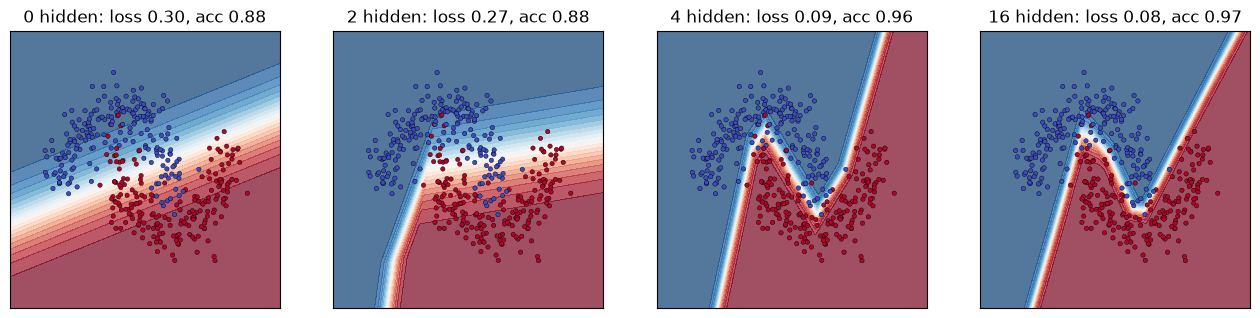

{0: (0.296, 0.877), 2: (0.265, 0.88), 4: (0.088, 0.96), 16: (0.083, 0.967)}


In [19]:
# Same data, same training; only the number of hidden neurons changes
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
moons_results = {}
for ax, hidden in zip(axes, [0, 2, 4, 16]):
    net = make_net(hidden)
    final_loss = train(net, Xm_t, ym_t)
    with torch.no_grad():
        acc = (net(Xm_t).argmax(1) == ym_t).float().mean().item()    # training accuracy
    moons_results[hidden] = (round(final_loss, 3), round(acc, 3))
    plot_boundary(net, ax, f"{hidden} hidden: loss {final_loss:.2f}, acc {acc:.2f}")
plt.show()
print(moons_results)     # {hidden neurons: (final loss, accuracy)}

**Plot / output** (`{hidden: (loss, train acc)}`):
- **0 hidden** (logistic regression): a straight boundary, loss 0.30, acc **0.877**. It gets the bulk right and misses the tips of the moons.
- **2 hidden**: still roughly straight with one bend, acc **0.88**. Two ReLUs can only bend the line once, and here the second neuron barely helps.
- **4 hidden**: a clear "V" that follows the curve, loss 0.09, acc **0.96**.
- **16 hidden**: the smoothest fit, loss 0.08, acc **0.967**.

Each ReLU neuron adds one "hinge", so the boundary is piecewise linear and more neurons means more pieces. From 4 to 16 the gain is small: the data has noise=0.2 and some points sit inside the other moon, so ~97% is close to the best possible here. These are *training* accuracies, so they show capacity, not generalisation. The same numbers as in class (0.88 / 0.88 / 0.96 / 0.97), because this part doesn't depend on my split.

### 7. Back to MILK10k — Session 5's 33 features

In [20]:
from PIL import Image
from scipy import ndimage

# ---- Session 5 ---------------------------------------------------------------
def color_stats(rgb):                                   # 6 features: mean and std of R, G, B
    return np.concatenate([rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])

def color_histogram(rgb, bins=8):                       # 24 features: 8-bin histogram per channel, as fractions of pixels
    n_pixels = rgb.shape[0] * rgb.shape[1]
    return np.concatenate([np.histogram(rgb[:, :, c], bins=bins, range=(0, 256))[0] / n_pixels
                           for c in range(3)])

def texture_features(rgb):                              # 3 features (Session 4 filters)
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    return np.array([np.hypot(gx, gy).mean(),                    # mean edge strength (Sobel magnitude)
                     (local_sq_mean - local_mean**2).mean(),      # mean local variance (9x9 window)
                     ndimage.laplace(gray).var()])               # sharpness (variance of the Laplacian)

def extract_features(isic_id):                          # 6 + 24 + 3 = 33 numbers per image
    rgb = np.array(Image.open(config.image_path(isic_id)).convert("RGB").resize((200, 150)), dtype=float)
    return np.concatenate([color_stats(rgb), color_histogram(rgb), texture_features(rgb)])
# ------------------------------------------------------------------------------------------

# My Milestone 1 splits: lesion-level, leak-free, seed 42 (replaces milk10k.make_splits from class)
train_df, val_df, test_df = [pd.read_csv(config.SPLIT_DIR / f"{s}.csv") for s in ("train", "val", "test")]
train_df, val_df, test_df = [d[d["image_type"] == "dermoscopic"].reset_index(drop=True)
                             for d in (train_df, val_df, test_df)]        # one image per lesion
for d in (train_df, val_df, test_df):
    assert d["lesion_id"].is_unique                                       # sanity: really one image per lesion
assert not set(train_df.lesion_id) & (set(val_df.lesion_id) | set(test_df.lesion_id))   # no leakage

cache = OUT / "features_33.npz"                     # extracting features from ~5,000 images is slow -> cache once
if cache.exists():
    data = np.load(cache, allow_pickle=True)
else:
    t0 = time.perf_counter()
    data = {f"X_{n}": np.stack([extract_features(i) for i in d["isic_id"]])
            for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    np.savez(cache, **data)
    print(f"{time.perf_counter() - t0:.0f} s")

X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
print(X_train.shape, X_val.shape, X_test.shape)

(3742, 33) (749, 33) (749, 33)


**Output.** Shapes `(3742, 33) (749, 33) (749, 33)`: one dermoscopic image per lesion with 33 features each. These are **my** Milestone 1 split sizes (70/15/15 % of 5,240 lesions, seed 42). The class split was 3,593 / 599 / 1,048, which is why my numbers below differ from the class comments. The asserts pass, so each lesion appears once and no train lesion is in val or test. The features came from the cache, so no extraction time is printed.

In [21]:
from sklearn.preprocessing import StandardScaler

CLASSES = ["Benign", "Indeterminate", "Malignant"]            # same order as my label_map.json (y_primary)
to_int = {c: i for i, c in enumerate(CLASSES)}
y_train = torch.tensor(train_df["diagnosis_1"].map(to_int).to_numpy())
y_val = torch.tensor(val_df["diagnosis_1"].map(to_int).to_numpy())
y_test = torch.tensor(test_df["diagnosis_1"].map(to_int).to_numpy())

# Neural nets need features on similar scales -> standardise (mean 0, std 1). Fit on TRAIN only (no leakage).
scaler = StandardScaler().fit(X_train)
Xtr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
Xva = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
Xte = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

print(Xtr.dtype, Xtr.shape, y_train[:10])
print(torch.bincount(y_train))                                # class counts: Benign, Indeterminate, Malignant

torch.float32 torch.Size([3742, 33]) tensor([2, 2, 2, 2, 0, 2, 2, 0, 2, 0])
tensor([1058,   88, 2596])


**Output.** The features are float32 tensors (what `nn.Linear` expects). The first 10 labels are mostly 2s (Malignant), with some 0s (Benign) and no 1s (Indeterminate). Class counts in train: **Benign 1,058 · Indeterminate 88 · Malignant 2,596**. So Malignant is 69% of the data and Indeterminate (all of it AKIEC) is only 2.4%. A model that always says "Malignant" would already get 69% accuracy, which is why we report **macro-F1** (the average F1 of the 3 classes) rather than accuracy.

In [22]:
# "balanced" class weights: n_samples / (n_classes * n_in_class) -> rare classes count more in the loss
class_weights = len(y_train) / (3 * torch.bincount(y_train).float())
class_weights

tensor([ 1.1790, 14.1742,  0.4805])

**Output.** Class weights **[1.18, 14.17, 0.48]**. One Indeterminate mistake costs about 14× a Benign one and about 30× a Malignant one in the loss, so the network can't just ignore the rare class. They're almost identical to the class values (1.18, 14.43, 0.48) because my split has the same proportions.

#### 7b. Session 5 baseline, retrained on my split

The class compares against Session 5's random forest (`baseline_scores.json`). I don't have that file, so I retrain the same kind of model here: a random forest on the same 33 features, the same split and the same labels. It uses `class_weight="balanced"` (same idea as the class weights above), 500 trees and `min_samples_leaf=5`. Trees don't need scaling, so it uses the raw features. I evaluate it on the test set only once and save it as `outputs/session_05/baseline_scores.json` so the scoreboard in section 10 reads it just as the class code does.

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

baseline_path = config.OUTPUT_DIR / "session_05" / "baseline_scores.json"
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=5,
                            random_state=0, n_jobs=-1).fit(X_train, y_train.numpy())
baseline = {"model": "Random forest (500 trees, balanced, min_samples_leaf=5) on the 33 features",
            "val_macro_f1": round(float(f1_score(y_val, rf.predict(X_val), average="macro")), 3),
            "test_macro_f1": round(float(f1_score(y_test, rf.predict(X_test), average="macro")), 3)}
baseline_path.parent.mkdir(parents=True, exist_ok=True)
baseline_path.write_text(json.dumps(baseline, indent=2))
RF_VAL_F1 = baseline["val_macro_f1"]          # the number to beat (validation)
baseline

{'model': 'Random forest (500 trees, balanced, min_samples_leaf=5) on the 33 features',
 'val_macro_f1': 0.534,
 'test_macro_f1': 0.578}

**Output.** On my split the random forest gets **val macro-F1 = 0.534** and **test macro-F1 = 0.578**. The validation value happens to equal the class's 0.534, but the test score is higher than the class's 0.495, partly because my test set is different and smaller (749 vs 1,048). That makes 0.534 on validation the number to beat in sections 8–11.

### 8. An MLP on MILK10k — mini-batches, epochs, curves

In [24]:
def make_mlp(hidden=(64,), dropout=0.0, seed=0, d_in=33):
    # d_in added by me (default 33 = class behaviour) so I can reuse it for raw pixels in the homework
    torch.manual_seed(seed)                     # same initial weights for everyone
    layers = []
    for h in hidden:                            # one Linear + ReLU (+ optional Dropout) block per hidden layer
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, 3))           # 3 logits, no softmax (it's inside the loss)
    return nn.Sequential(*layers)

model = make_mlp()
print(model)
print(sum(p.numel() for p in model.parameters()))        # (33*64 + 64) + (64*3 + 3) = 2,371 weights

Sequential(
  (0): Linear(in_features=33, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=3, bias=True)
)
2371


**Output.** The architecture is 33 → 64 (ReLU) → 3, with **2,371 parameters**: (33·64 + 64) + (64·3 + 3). That's tiny for a neural network, and only about 1.6 training examples per weight.

In [25]:
from torch.utils.data import TensorDataset, DataLoader

# Mini-batches: instead of using all training images for every update, take 64 at a time (shuffled each epoch)
train_loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=64, shuffle=True)
print(len(train_loader))                                  # batches per epoch = ceil(n_train / 64)
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                                 # one batch: 64 rows x 33 features, 64 labels

59
torch.Size([64, 33]) torch.Size([64])


**Output.** There are **59 mini-batches per epoch** (⌈3,742 / 64⌉; the last one has only 30 images). In class it was 57 because their training set was smaller. One batch is `[64, 33]` inputs plus 64 labels. Each epoch therefore makes 59 small weight updates instead of 1 big one. That's cheaper per step, and the noise from shuffling helps escape poor regions of the loss surface.

In [26]:
def fit(model, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64, data=None):
    # data=(X_train, y_train, X_val, y_val) added by me for the homework; None = the 33-feature tensors (class behaviour)
    Xtr_, ytr_, Xva_, yva_ = data if data is not None else (Xtr, y_train, Xva, y_val)
    loader = DataLoader(TensorDataset(Xtr_, ytr_), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # weight_decay = L2 penalty
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)          # weighted -> Indeterminate errors cost ~13x more
    history = []
    for epoch in range(epochs):
        model.train()                                            # training mode (dropout ON)
        total = 0.0
        for xb, yb in loader:                                    # the 4-step loop, once per mini-batch
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)                       # sum of per-sample losses for the epoch average
        model.eval()                                             # evaluation mode (dropout OFF)
        with torch.no_grad():                                    # after every epoch, score the validation set
            val_logits = model(Xva_)
            history.append({"epoch": epoch,
                            "train_loss": total / len(Xtr_),
                            "val_loss": loss_fn(val_logits, yva_).item(),
                            "val_f1": f1_score(yva_, val_logits.argmax(1), average="macro")})
    return pd.DataFrame(history).set_index("epoch")

t0 = time.perf_counter()
model = make_mlp()
hist = fit(model)
print(f"{time.perf_counter() - t0:.0f} s")
hist.iloc[[0, 9, 19, 29, 39, 49]].round(3)        # a few snapshots of the 50 epochs

10 s


,train_loss,val_loss,val_f1
epoch,,,
0,1.040,0.998,0.413
9,0.784,0.972,0.432
19,0.730,1.023,0.468
29,0.695,1.070,0.476
39,0.665,1.129,0.498
49,0.633,1.178,0.479


**Output.** The run took 10 s on my laptop CPU.
- **train loss** goes down steadily: 1.040 → 0.633.
- **val loss** is lowest around epoch 5–10 (~0.95) and then **rises** to 1.178. That's the start of overfitting: the network keeps getting better on training images and worse on new ones.
- **val macro-F1** still climbs from 0.41 to about 0.48–0.50 and then plateaus (0.479 at the end, best 0.498 at epoch 39).

The loss and F1 disagree because the loss also measures *confidence*. Late in training the model gets more extreme (over-confident) on the val images it gets wrong, which raises the loss, while the *argmax* decision that F1 uses keeps improving slightly. Same pattern as in class (class: val loss 1.068, F1 0.493).

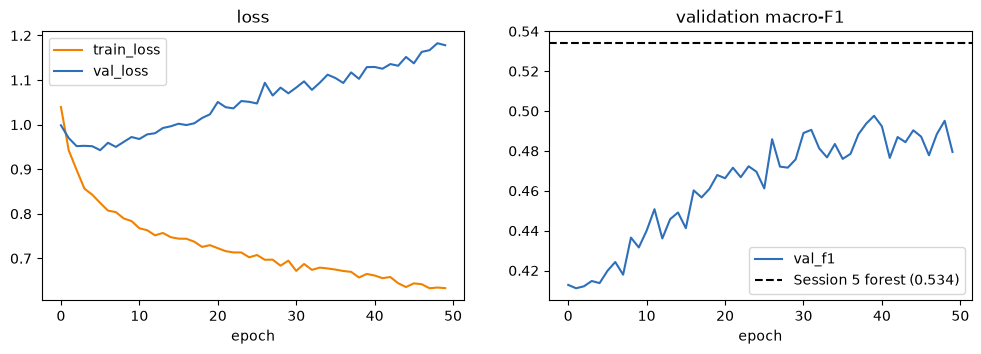

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=axes[0], color=["#F08200", "#2E6FBA"], title="loss")
hist["val_f1"].plot(ax=axes[1], color="#2E6FBA", title="validation macro-F1")
axes[1].axhline(RF_VAL_F1, color="k", ls="--", label=f"Session 5 forest ({RF_VAL_F1})")   # my forest, not the class 0.534
axes[1].legend();

**Plot.** On the left, the gap between train (orange) and val (blue) loss opens from about epoch 5 onward: the textbook overfitting signature. On the right, val macro-F1 rises noisily and plateaus around 0.48–0.50, **always below the forest's dashed line at 0.534**. The epoch-to-epoch jumps (±0.02) come from shuffled mini-batches and the small Indeterminate class: with only 18 val examples, one more or one fewer correct changes that class's F1 by a lot.

In [28]:
model.eval()
with torch.no_grad():
    val_pred = model(Xva).argmax(1)                # predicted class = highest logit
mlp_val_f1 = f1_score(y_val, val_pred, average="macro")
print(f"MLP val macro-F1 = {mlp_val_f1:.3f}   (Session 5 forest on my split: {RF_VAL_F1})")

MLP val macro-F1 = 0.479   (Session 5 forest on my split: 0.534)


**Output.** The MLP gets **0.479** on validation against **0.534** for the forest, so on the same 33 features it is *worse* by about 0.055. This isn't surprising. On a small table of hand-crafted features, tree ensembles are very hard to beat: they handle different feature scales and interactions without tuning. The MLP's advantage only appears when it can learn its own features from raw data, which is what CNNs (Session 7) are for.

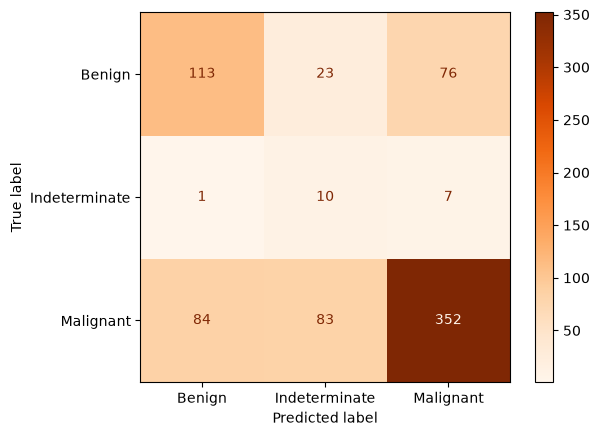

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=CLASSES, cmap="Oranges");

**Plot** (rows = truth, columns = prediction, 749 val lesions):
- **Benign** (212): 113 correct (recall 53%). 76 are called Malignant, which is safe but creates unnecessary work-ups, and 23 Indeterminate.
- **Indeterminate** (18): 10 correct (recall 56%), but 116 lesions are *predicted* Indeterminate, so precision is only 10/116 ≈ 9%. That's the side effect of the ×14 class weight: the model over-uses the rare class.
- **Malignant** (519): 352 correct (recall 68%). The worrying cell is **84 malignant lesions predicted Benign** (16%). Clinically that's the dangerous error, because those lesions would be sent home.

Overall accuracy is (113 + 10 + 352) / 749 ≈ 63%.

### 9. Overfitting on purpose — and three cures

75267


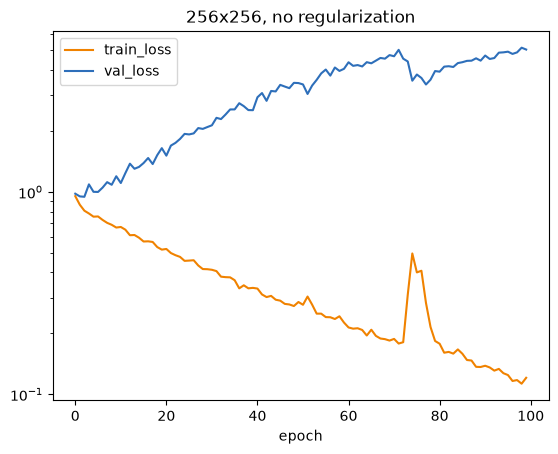

In [30]:
# A much bigger network (two hidden layers of 256) on only ~3,700 images: it will memorise
big = make_mlp(hidden=(256, 256))
print(sum(p.numel() for p in big.parameters()))           # 33*256+256 + 256*256+256 + 256*3+3
hist_big = fit(big, epochs=100)
hist_big[["train_loss", "val_loss"]].plot(color=["#F08200", "#2E6FBA"], logy=True,
                                          title="256x256, no regularization");

**Plot.** The 256×256 network has **75,267 weights**, about 20 per training image, so it can memorise. Train loss (log scale) falls all the way to about 0.12, while val loss climbs from about 1 to about 5. That's severe overfitting: the network is very confident on new images and often wrong. The spike around epoch 75 is Adam taking an oversized step and recovering, a sign of training a huge model with no regularisation.

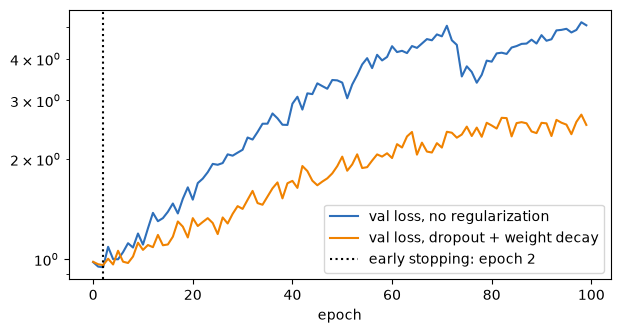

{'train_loss': 0.121, 'val_loss': 5.049, 'val_f1': 0.504}
{'train_loss': 0.406, 'val_loss': 2.533, 'val_f1': 0.506}
best val F1 during training: 0.54 (big) / 0.549 (reg)


In [31]:
# Cures 1 + 2: dropout (randomly switch off 30% of hidden neurons while training) + weight decay (L2 on weights)
reg = make_mlp(hidden=(256, 256), dropout=0.3)
hist_reg = fit(reg, epochs=100, weight_decay=1e-4)

fig, ax = plt.subplots(figsize=(7, 3.5))
hist_big["val_loss"].plot(ax=ax, label="val loss, no regularization", color="#2E6FBA", logy=True)
hist_reg["val_loss"].plot(ax=ax, label="val loss, dropout + weight decay", color="#F08200")
# Cure 3: early stopping = keep the model from the epoch with the lowest validation loss
best_epoch = hist_reg["val_loss"].idxmin()
ax.axvline(best_epoch, color="k", ls=":", label=f"early stopping: epoch {best_epoch}")
ax.legend();
plt.show()
print(hist_big.iloc[-1].round(3).to_dict())     # last epoch, no regularisation
print(hist_reg.iloc[-1].round(3).to_dict())     # last epoch, dropout + weight decay
print("best val F1 during training:", round(hist_big.val_f1.max(), 3), "(big) /", round(hist_reg.val_f1.max(), 3), "(reg)")

**Plot / output.**
- **No regularisation**: final train loss 0.121, val loss **5.05**, val F1 0.504.
- **Dropout 0.3 + weight decay 1e-4**: train loss 0.406 (it can't memorise as easily), val loss **2.53**, so about half, and val F1 0.506.
- **Early stopping**: the lowest val loss is at **epoch 2**, so stopping there gives the best-calibrated model.

Regularisation clearly helps the *loss*, which roughly halves, but the final F1 barely moves (0.504 → 0.506). The best F1 seen during training was 0.540 (big) and **0.549** (reg), slightly above the forest. That peak was chosen by looking at validation every epoch, so it's optimistic. Note also that early stopping on val *loss* (epoch 2) would stop far too early for *F1*, which peaks much later. With a weighted loss and macro-F1 as the metric, it would be better to early-stop on **val F1**. The three cures (dropout, weight decay, early stopping) all reduce how much the network can memorise; they don't add new information.

### 10. The test set — once — and the scoreboard

In [32]:
# The model chosen BEFORE looking at test: the class MLP 33-64-3 from section 8
with torch.no_grad():
    test_pred = model(Xte).argmax(1)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
print(f"TEST accuracy = {test_acc:.3f}   TEST macro-F1 = {test_f1:.3f}")

baseline = json.loads(baseline_path.read_text())     # written in 7b (class: session_05_classical_ml/_output/...)
scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": [baseline["val_macro_f1"], baseline["test_macro_f1"]],
    "Session 6 - MLP 33-64-3 (33 features)": [round(mlp_val_f1, 3), round(test_f1, 3)],
}, index=["val macro-F1", "test macro-F1"]).T
scoreboard

TEST accuracy = 0.666   TEST macro-F1 = 0.513


,val macro-F1,test macro-F1
Session 5 - random forest (33 features),0.534,0.578
Session 6 - MLP 33-64-3 (33 features),0.479,0.513


**Output.** Opening the test set once for the model chosen in section 8 (33-64-3) gives **test accuracy 0.666, test macro-F1 0.513**.

| | val macro-F1 | test macro-F1 |
|---|---|---|
| Session 5 forest | 0.534 | 0.578 |
| Session 6 MLP | 0.479 | 0.513 |

The ranking holds on test: the forest beats the MLP by about 0.06 on both sets, so the validation result wasn't a fluke. Test scores are a bit higher than validation for both models, which is just sampling noise between two 749-lesion sets (only 17–18 Indeterminate lesions in each).

In [33]:
scores = {"model": "MLP 33-64-3 on Session 5's 33 handcrafted features",
          "val_macro_f1": round(float(mlp_val_f1), 3),
          "test_accuracy": round(float(test_acc), 3),
          "test_macro_f1": round(float(test_f1), 3)}
(OUT / "mlp_scores.json").write_text(json.dumps(scores, indent=2))    # saved for Session 7's scoreboard
scores

{'model': "MLP 33-64-3 on Session 5's 33 handcrafted features",
 'val_macro_f1': 0.479,
 'test_accuracy': 0.666,
 'test_macro_f1': 0.513}

### 11. Mini challenge — tune it

Change **one thing at a time**, train, and note the final **validation** macro-F1:

1. learning rate: `lr=0.1`, then `lr=1e-5`
2. width: `hidden=(4,)`, then `hidden=(256,)`
3. depth: `hidden=(64, 64)`

Number to beat: Session 5's random forest (on my split: see 7b). The test set stays closed.

In [34]:
# Every run starts from the class default (hidden=(64,), lr=1e-3, 50 epochs, seed 0) and changes ONE thing
experiments = {
    "default  (64,), lr=1e-3": dict(),
    "lr = 0.1":                dict(lr=0.1),
    "lr = 1e-5":               dict(lr=1e-5),
    "width (4,)":              dict(hidden=(4,)),
    "width (256,)":            dict(hidden=(256,)),
    "depth (64, 64)":          dict(hidden=(64, 64)),
}
rows, histories = [], {}
for name, cfg in experiments.items():
    cfg = dict(cfg)
    m = make_mlp(hidden=cfg.pop("hidden", (64,)))
    h = fit(m, **cfg)
    histories[name] = h
    rows.append({"experiment": name,
                 "params": sum(p.numel() for p in m.parameters()),
                 "final train loss": h.train_loss.iloc[-1],
                 "final val loss": h.val_loss.iloc[-1],
                 "final val F1": h.val_f1.iloc[-1],
                 "best val F1 (epoch)": f"{h.val_f1.max():.3f} ({h.val_f1.idxmax()})"})
challenge = pd.DataFrame(rows).set_index("experiment").round(3)
challenge["beats forest?"] = challenge["final val F1"] > RF_VAL_F1
challenge

,params,final train loss,final val loss,final val F1,best val F1 (epoch),beats forest?
experiment,,,,,,
"default (64,), lr=1e-3",2371,0.633,1.178,0.479,0.498 (39),False
lr = 0.1,2371,0.888,1.906,0.295,0.494 (39),False
lr = 1e-5,2371,1.023,1.038,0.378,0.378 (49),False
"width (4,)",151,0.794,0.993,0.444,0.445 (33),False
"width (256,)",9475,0.530,1.426,0.511,0.521 (32),False
"depth (64, 64)",6531,0.465,2.266,0.504,0.513 (47),False


**Output** (one change at a time; default = 64 hidden, lr 1e-3, 50 epochs; forest = 0.534):

| change | final val F1 | what happened |
|---|---|---|
| default | 0.479 | reference |
| **lr = 0.1** | 0.295 | **Too big.** Train loss stays high (0.89) and val F1 jumps around between about 0.2 and 0.5: Adam overshoots every step, like the lr = 1.1 plot in section 4. |
| **lr = 1e-5** | 0.378 | **Too small.** After 50 epochs the loss has barely moved (1.02) and F1 is still rising slowly. The network is under-trained, not bad; it would need thousands of epochs. |
| **width 4** | 0.444 | **Too little capacity** (151 weights). The lowest val loss (0.99) and the least overfitting, but it can't represent enough patterns, so F1 is low. It underfits. |
| **width 256** | **0.511** | Best final F1 (best 0.521 at epoch 32). More capacity helps F1 even though val loss rises (1.43), meaning it overfits in confidence. |
| **depth (64, 64)** | 0.504 | Similar F1 to width 256, but the most overfitting: train loss 0.47, val loss **2.27**. Two layers memorise faster. |

**None of the 5 changes beats the forest (0.534).** The learning rate matters most: both extremes are far worse than the default. More capacity (wider or deeper) gives small F1 gains of about +0.03, at the cost of more overfitting, so it should come with the dropout and weight decay from section 9. All runs use the same seed, so the differences come from the settings, not the initialisation. With one seed each, though, differences of ±0.02 are within the noise.

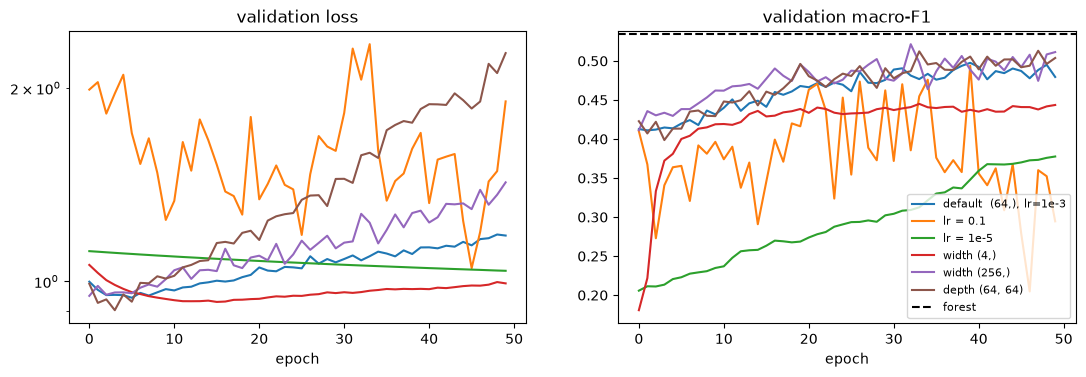

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, h in histories.items():
    h["val_loss"].plot(ax=axes[0], label=name)
    h["val_f1"].plot(ax=axes[1], label=name)
axes[0].set_title("validation loss"); axes[0].set_yscale("log")
axes[1].set_title("validation macro-F1"); axes[1].axhline(RF_VAL_F1, color="k", ls="--", label="forest")
axes[1].legend(fontsize=8, loc="lower right");

**Plot.** On the left (val loss, log scale), lr = 0.1 (orange) is erratic and high, lr = 1e-5 (green) is flat and slowly decreasing, width 4 (red) is the lowest and flattest, and deeper/wider models rise fastest (overfitting). On the right (val F1), the default, width 256 and depth (64, 64) cluster around 0.48–0.52, width 4 plateaus around 0.44, lr = 1e-5 is still climbing at 0.38, and lr = 0.1 jumps between 0.2 and 0.5 from epoch to epoch. No curve stays above the forest line.

### Homework · Before Session 7

1. Add your MLP's validation and test macro-F1 to the scoreboard, next to your Session 5's baseline.
2. Read the docs of nn.Conv2d: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than your baseline with features? Why?

**My Session 5 baseline** is the one from my classical-baseline homework (Milestone 2, `scripts/10_model_selection.py` + `11_final_evaluation.py`): class-balanced **logistic regression (C = 0.01) on 306 hand-crafted features** (colour, histograms, texture and shape of the dermoscopic *and* clinical image, plus age / sex / site). Same lesion-level split and same 749 test lesions as this notebook. It was chosen on validation and its test score was computed once. I read its scores from `outputs/classical/`. The class random forest on the 33 features (section 7b) stays on the scoreboard as a reference.

#### Homework 3 — the MLP on raw pixels (done first so its result can go on the scoreboard)

torch.Size([3742, 3072]) torch.Size([749, 3072]) torch.Size([749, 3072])


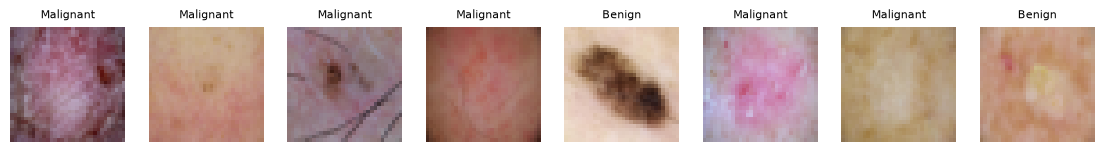

In [36]:
# Each dermoscopic image -> resized to 32x32 RGB -> flattened to 3,072 numbers. No hand-crafted features.
def raw_pixels(isic_id, size=32):
    return np.array(Image.open(config.image_path(isic_id)).convert("RGB").resize((size, size)), dtype=np.uint8)

pix_cache = OUT / "pixels_32.npz"
if pix_cache.exists():
    pix = np.load(pix_cache)
else:
    t0 = time.perf_counter()
    pix = {f"P_{n}": np.stack([raw_pixels(i) for i in d["isic_id"]])
           for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    np.savez_compressed(pix_cache, **pix)
    print(f"{time.perf_counter() - t0:.0f} s")

P_train, P_val, P_test = [pix[f"P_{n}"].reshape(len(pix[f"P_{n}"]), -1).astype(np.float32)
                          for n in ("train", "val", "test")]          # (n, 32, 32, 3) -> (n, 3072)
pix_scaler = StandardScaler().fit(P_train)                            # standardise every pixel position, train only
Ptr, Pva, Pte = [torch.tensor(pix_scaler.transform(a), dtype=torch.float32) for a in (P_train, P_val, P_test)]
print(Ptr.shape, Pva.shape, Pte.shape)

# Look at what the network actually gets: 8 training images at 32x32
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, i in zip(axes, range(8)):
    ax.imshow(pix["P_train"][i]); ax.set_title(CLASSES[y_train[i]], fontsize=8); ax.axis("off")

**Output.** Each image becomes 3,072 numbers (32 × 32 × 3), standardised per pixel position using the training set only. The thumbnails show what the network sees: at 32×32 the border and colour of the lesion are still visible, but fine texture (dots, streaks, vessels) is mostly gone. Hairs (3rd image) are still there and add noise. Many malignant lesions (mostly BCC) are pale pink patches that look a lot like normal skin at this size.

In [37]:
pix_data = (Ptr, y_train, Pva, y_val)

# (a) Exactly the class recipe, only the input changes: 3072-64-3
pix_mlp = make_mlp(hidden=(64,), d_in=3072)
print("params:", sum(p.numel() for p in pix_mlp.parameters()))       # 3072*64+64 + 64*3+3
t0 = time.perf_counter()
hist_pix = fit(pix_mlp, data=pix_data)
print(f"{time.perf_counter() - t0:.0f} s")

# (b) Same, with the section 9 cures (dropout + weight decay) - the fairer version for so many inputs
pix_mlp_reg = make_mlp(hidden=(64,), dropout=0.3, d_in=3072)
hist_pix_reg = fit(pix_mlp_reg, weight_decay=1e-3, data=pix_data)

pix_vs = pd.DataFrame({
    "33 features, 33-64-3":            hist.iloc[-1],
    "raw pixels, 3072-64-3":           hist_pix.iloc[-1],
    "raw pixels, 3072-64-3 + dropout/wd": hist_pix_reg.iloc[-1],
}).T.round(3)
pix_vs["params"] = [2371, sum(p.numel() for p in pix_mlp.parameters()), sum(p.numel() for p in pix_mlp_reg.parameters())]
pix_vs["best val F1 during training"] = [round(hist.val_f1.max(), 3), round(hist_pix.val_f1.max(), 3), round(hist_pix_reg.val_f1.max(), 3)]
pix_vs

params: 196867
11 s


,train_loss,val_loss,val_f1,params,best val F1 during training
"33 features, 33-64-3",0.633,1.178,0.479,2371,0.498
"raw pixels, 3072-64-3",0.163,3.273,0.485,196867,0.507
"raw pixels, 3072-64-3 + dropout/wd",0.585,3.103,0.457,196867,0.511


**Output.**
- **3072-64-3** has **196,867 parameters** (83× more than the 33-feature MLP, about 53 per training image). Final val F1 is **0.485** (best 0.507). Train loss drops to 0.163 while val loss rises to **3.27**, so it massively overfits: it memorises the 3,742 training images.
- **With dropout 0.3 + weight decay 1e-3**, train loss stays at 0.585 and val loss is 3.10. Final F1 is 0.457 (best 0.511), so regularisation barely helps here.
- **33 features**: 0.479 final, best 0.498.

On validation, raw pixels and 33 features end up **about equal** (0.485 vs 0.479; the difference is noise), and both stay below the forest.

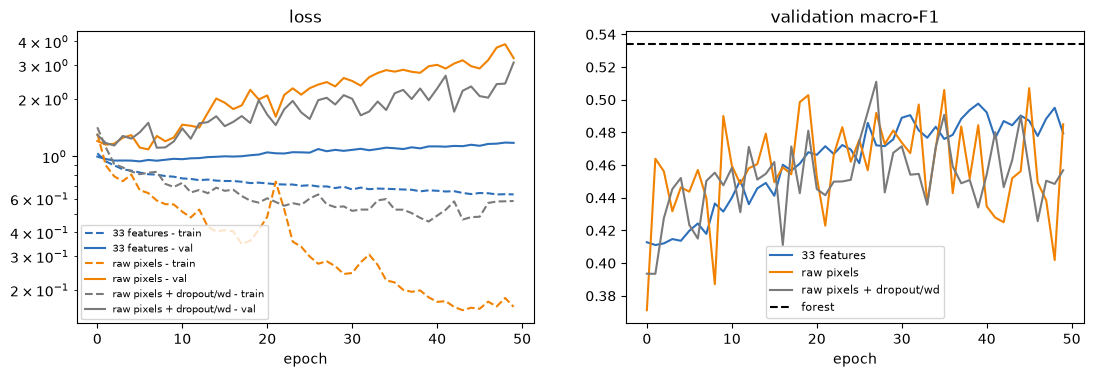

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, h), c in zip([("33 features", hist), ("raw pixels", hist_pix), ("raw pixels + dropout/wd", hist_pix_reg)],
                        ["#2E6FBA", "#F08200", "#7A7A7A"]):
    h["train_loss"].plot(ax=axes[0], color=c, ls="--", label=f"{name} - train")
    h["val_loss"].plot(ax=axes[0], color=c, label=f"{name} - val")
    h["val_f1"].plot(ax=axes[1], color=c, label=name)
axes[0].set_yscale("log"); axes[0].set_title("loss"); axes[0].legend(fontsize=7)
axes[1].axhline(RF_VAL_F1, color="k", ls="--", label="forest"); axes[1].set_title("validation macro-F1"); axes[1].legend(fontsize=8);

**Plot.** On the left, the raw-pixel train loss (dashed orange) falls far lower than the 33-feature one (dashed blue), while its val loss (solid orange) climbs about 3× higher. That's much stronger overfitting for the same final F1. The spike around epoch 20 is another Adam overshoot. On the right, the raw-pixel F1 curves are much noisier (±0.05 from epoch to epoch) than the 33-feature curve: the model's decisions on val images are unstable because it relies on memorised pixel patterns rather than robust features.

#### Homework 3 — answer: better or worse than my baseline with features? Why?

**Worse.** The raw-pixel MLP gets **val macro-F1 0.485 / test 0.507**. My Session 5 baseline (logistic regression on 306 hand-crafted features) gets **0.545 / 0.550**. That's **−0.06 on validation and −0.04 on test**, and the raw-pixel model needs **196,867 weights** to get there, against **921** for the logistic regression (306 × 3 + 3). It's also worse than the class forest on the 33 features (0.534 / 0.578). It's only about as good as the MLP on those same 33 features (0.479 / 0.513), and with 83× more weights, ~3× higher val loss and much noisier training.

**Is the comparison fair?** Not completely. My baseline also sees the clinical image and the metadata, and the raw-pixel MLP only sees the dermoscopic image. My Session 5 model-selection table lets me check the image-only part: with only the **149 dermoscopic features** (set F5), logistic regression gets val macro-F1 **0.486**, the same as raw pixels, while gradient boosting on those same features reaches **0.585**. So part of the gap comes from extra information (metadata + second view), but well-chosen features with a good model still beat raw pixels clearly.

**Why raw pixels do worse, even though they contain "all" the information:**
1. **Too many parameters for 3,742 images.** That's 196,867 weights, about 53 per training image. The network memorises the training set (train loss 0.16) instead of learning general rules, which is the val-loss explosion in the plot (3.27 vs 1.18 for 33 features). My baseline is a strongly regularised (C = 0.01) linear model with 921 weights, so it can't memorise.
2. **An MLP ignores image structure.** It sees 3,072 independent numbers. It doesn't know pixel (10, 10) and pixel (10, 11) are neighbours, and a lesion shifted 3 pixels is a completely different input. It must learn every pattern separately at every position, which needs far more data than we have.
3. **32×32 throws away the useful detail.** Dermoscopic clues (pigment network, dots, streaks, vessels, irregular borders) are finer than a 32×32 grid can hold, so mostly overall colour survives. My baseline's features are computed at **full resolution**: Sobel, multi-scale LoG, local std, Canny edges, entropy.
4. **My features carry prior knowledge (domain knowledge).** They measure exactly what dermatologists look at: lesion-vs-skin colour contrast (ΔE in CIELab), colour variegation, and ABCD-style shape of a colour-aware lesion mask (asymmetry, compactness, solidity). They are also translation-invariant. Raw pixels have to discover all of this from scratch.
5. **Metadata.** In my Session 5 permutation importance, metadata was the most useful group (−0.118 balanced accuracy when shuffled), mostly age. The pixel MLP doesn't get it.

**What this sets up for Session 7.** The fix isn't more hand-crafted features. It's an architecture that builds in the right assumptions: **convolutions** (homework 2). A CNN shares the same small kernel across every position (few weights, translation-equivariant) and stacks layers to build edges → textures → lesion parts, like my Sobel/LoG features but learned. Its parameter count doesn't grow with image size, so it can also work at higher resolution than 32×32. That is the model that has to beat my baseline (0.550 test macro-F1), especially on melanoma recall.

#### Homework 1 — the scoreboard

In [39]:
# Test set: each model below was fixed BEFORE its test score was computed; nothing was re-tuned after.
pix_mlp.eval()
with torch.no_grad():
    pix_test_f1 = f1_score(y_test, pix_mlp(Pte).argmax(1), average="macro")

# MY Session 5 baseline (classical-baseline homework): read from its saved outputs, nothing retrained here
sel = json.loads((config.OUTPUT_DIR / "classical" / "selected.json").read_text())
cls_test = pd.read_csv(config.OUTPUT_DIR / "classical" / "test_metrics.csv", index_col=0)["selected_model"]
my_baseline = {"val_macro_f1": round(sel["val_macro_f1"], 3), "test_macro_f1": round(float(cls_test["macro_f1"]), 3)}
print(f"My Session 5 baseline: {sel['model']} (C={sel['params']['C']}) on {sel['feature_set']} "
      f"({sel['n_features']} features), test fit on {sel['trained_on']}")

scoreboard = pd.DataFrame({
    "Session 5 - MY baseline: LogReg, 306 features":  [my_baseline["val_macro_f1"], my_baseline["test_macro_f1"]],
    "Session 5 (class) - random forest, 33 features": [baseline["val_macro_f1"], baseline["test_macro_f1"]],
    "Session 6 - MLP 33-64-3 (33 features)":          [round(mlp_val_f1, 3), round(test_f1, 3)],
    "Session 6 HW - MLP 3072-64-3 (raw pixels)":      [round(hist_pix.val_f1.iloc[-1], 3), round(pix_test_f1, 3)],
}, index=["val macro-F1", "test macro-F1"]).T
scoreboard["test Δ vs my baseline"] = (scoreboard["test macro-F1"] - my_baseline["test_macro_f1"]).round(3)
scoreboard.to_csv(OUT / "scoreboard.csv")
scores["my_session5_baseline"] = {"model": "LogReg C=0.01, F7 (306 features: 2 views + metadata)", **my_baseline}
scores["raw_pixels_val_macro_f1"] = round(float(hist_pix.val_f1.iloc[-1]), 3)
scores["raw_pixels_test_macro_f1"] = round(float(pix_test_f1), 3)
(OUT / "mlp_scores.json").write_text(json.dumps(scores, indent=2))
scoreboard

My Session 5 baseline: LogReg (C=0.01) on F7_all_2views_meta (306 features), test fit on train+val


,val macro-F1,test macro-F1,test Δ vs my baseline
"Session 5 - MY baseline: LogReg, 306 features",0.545,0.550,0.000
"Session 5 (class) - random forest, 33 features",0.534,0.578,0.028
Session 6 - MLP 33-64-3 (33 features),0.479,0.513,-0.037
Session 6 HW - MLP 3072-64-3 (raw pixels),0.485,0.507,-0.043


**Output** (all on my lesion-level split, same 749 test lesions; test opened once per model, after it was fixed):

| model | val macro-F1 | test macro-F1 | test Δ vs my baseline |
|---|---|---|---|
| **Session 5 — my baseline:** LogReg, 306 features (2 views + metadata) | **0.545** | **0.550** | — |
| Session 5 (class reference): random forest, 33 features | 0.534 | 0.578 | +0.028 |
| Session 6: MLP 33-64-3, 33 features | 0.479 | 0.513 | -0.037 |
| Session 6 HW: MLP 3072-64-3, raw 32×32 pixels | 0.485 | 0.507 | -0.043 |

- **Both MLPs are below my baseline**, by about 0.06 on validation and 0.04 on test. The two MLPs are within noise of each other.
- The class forest has a higher macro-F1 than my baseline (0.578 vs 0.550 on test). That's mainly because my baseline was **selected on balanced accuracy**, not macro-F1 (its test balanced accuracy is 0.669). It recalls 59 % of the rare Indeterminate lesions but with precision 0.11, which pulls its macro-F1 down. In my Session 5 comparison, tree models predicted almost no Indeterminate: that costs balanced accuracy but much less macro-F1. The two baselines are within each other's bootstrap CI (my baseline: test macro-F1 95 % CI 0.508–0.594).
- Small caveat: my baseline's validation score comes from the model fitted on train, while its test score comes from the refit on train+val (4,491 lesions). The MLPs were only ever trained on train.
- The scoreboard is saved to `outputs/session_06/scoreboard.csv`, and all scores (including my baseline's) to `outputs/session_06/mlp_scores.json` for Session 7.

#### Homework 2 — `nn.Conv2d` vs Session 4

Signature from the PyTorch docs:

```python
torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0,
                dilation=1, groups=1, bias=True, padding_mode='zeros')
```

| Session 4 concept | `nn.Conv2d` argument | Notes |
|---|---|---|
| kernel size *k* (3×3 Sobel, 5×5 Gaussian…) | `kernel_size` | int (`3`) or tuple (`(3, 5)`) |
| stride *s* (how far the window jumps) | `stride` | default 1 = every position, like our `conv2d` loop |
| padding *p* (pixels added around the border) | `padding` | int, tuple, or `'same'` / `'valid'` |
| padding **type** (zero vs replicate/mirror) | `padding_mode` | `'zeros'` (default), `'reflect'`, `'replicate'`, `'circular'` |

**Same output-size formula as Session 4.** `out = floor((N + 2p − k) / s) + 1`. With p = 0 and s = 1 this reduces to Session 4's **N − k + 1**.

**Two differences from Session 4.**
1. **The kernel values are learned.** In Session 4 we picked the numbers (Sobel, Gaussian…). In `nn.Conv2d` they live in `conv.weight` (shape `out_channels × in_channels × k × k`) and backprop learns them, just like the MLP weights above. Every layer also learns **many** kernels at once (`out_channels`), and each one looks at all input channels (`in_channels`, e.g. 3 for RGB), not a single grayscale image.
2. **No kernel flip.** PyTorch's "convolution" is a cross-correlation: the kernel is not flipped. That's the same operation as `scipy.ndimage.correlate`, which I used to check my hand-written `conv2d` in Session 4.

The other arguments: `dilation` spreads the kernel taps apart (a 3×3 kernel with dilation 2 covers a 5×5 area), `groups` splits the channels into independent groups, and `bias` adds one learned constant per output channel.

The cell below checks this on a real lesion. I build an `nn.Conv2d` with `kernel_size=3, stride=1, padding=1, padding_mode='replicate'`, load the Session 4 Sobel-x kernel into its weights, and compare the result with `scipy.ndimage.correlate`. I also try stride 2 and no padding to confirm the size formula.

conv weight shape: (1, 1, 3, 3) | output: (150, 200) | max |torch - scipy| = 0.0
k=3 s=1 p=0: torch 148x198  formula 148x198
k=3 s=1 p=1: torch 150x200  formula 150x200
k=3 s=2 p=1: torch 75x100  formula 75x100
k=5 s=2 p=0: torch 73x98  formula 73x98


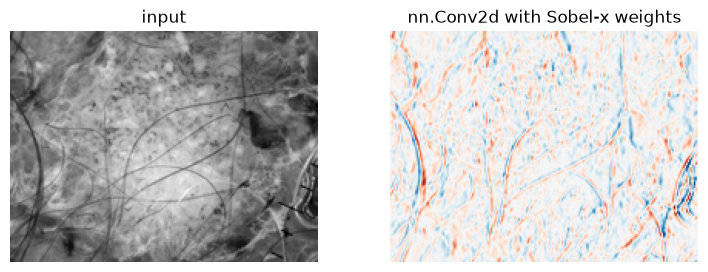

In [40]:
gray = np.array(Image.open(config.image_path(train_df.isic_id[0])).convert("L").resize((200, 150)), dtype=np.float32)
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)    # Session 4 kernel

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1,
                 padding_mode="replicate", bias=False)
with torch.no_grad():
    conv.weight[:] = torch.from_numpy(sobel_x).view(1, 1, 3, 3)    # hand-set instead of learned
    torch_out = conv(torch.from_numpy(gray)[None, None])[0, 0].numpy()   # input shape: (batch, channels, H, W)

scipy_out = ndimage.correlate(gray, sobel_x, mode="nearest")      # 'nearest' = replicate padding
print("conv weight shape:", tuple(conv.weight.shape), "| output:", torch_out.shape,
      "| max |torch - scipy| =", float(np.abs(torch_out - scipy_out).max()))

# Output size = floor((N + 2p - k) / s) + 1
for k, s, p in [(3, 1, 0), (3, 1, 1), (3, 2, 1), (5, 2, 0)]:
    c = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p)
    H, W = c(torch.zeros(1, 1, 150, 200)).shape[-2:]
    print(f"k={k} s={s} p={p}: torch {H}x{W}  formula {(150 + 2*p - k)//s + 1}x{(200 + 2*p - k)//s + 1}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("input"); axes[0].axis("off")
axes[1].imshow(torch_out, cmap="RdBu_r"); axes[1].set_title("nn.Conv2d with Sobel-x weights"); axes[1].axis("off");

**Output.**
- The weight shape is `(1, 1, 3, 3)` = (out_channels, in_channels, k, k).
- `nn.Conv2d` with Sobel-x weights and replicate padding gives a **max difference of 0.0** from `scipy.ndimage.correlate(mode='nearest')`. So PyTorch's convolution is exactly Session 4's cross-correlation, with `padding_mode='replicate'` = scipy's `'nearest'`.
- Output sizes match the formula in every case:
  - k = 3, p = 0 → 148×198 (N − k + 1, the Session 4 formula)
  - k = 3, p = 1 → 150×200 ("same" size)
  - stride 2 → 75×100 (half resolution)
  - k = 5, s = 2, p = 0 → 73×98

The plot shows Sobel-x highlighting the left and right borders of the lesion with opposite signs (red/blue), as in Session 4. In a CNN these 9 numbers would be learned instead of set by hand.

### Summary of Session 6

- **One neuron** = weighted sum + activation = logistic regression → a straight-line boundary only. It **can't do XOR**.
- **Hidden layer + non-linearity (ReLU)** maps the data into a new space where a line works. Without the non-linearity, stacked layers collapse into one linear layer.
- **Softmax** turns logits into probabilities. **Cross-entropy** = −log(p of the true class), which punishes confident mistakes hardest.
- **Gradient descent**: w ← w − lr·∇L. The learning rate decides between too slow, good and diverging.
- **Backprop** = the chain rule, checked by hand against PyTorch autograd (identical gradients).
- **More hidden neurons** → more bends in the boundary (moons: 0.88 → 0.97 train acc).
- **On MILK10k (my split)**: MLP 33-64-3 val F1 0.479 / test 0.513, below the random forest (0.534 / 0.578). Big MLPs overfit fast. Dropout and weight decay halve the val loss but barely move F1.
- **Tuning**: lr is the most sensitive setting. Width 256 or depth 2 give about +0.03 F1. Nothing beats the forest.
- **Raw pixels**: worse than my Session 5 baseline (LogReg on 306 features: test macro-F1 0.507 vs 0.550), and only as good as the MLP on 33 features, with 83× the weights and much more overfitting. An MLP has no notion of neighbouring pixels → **we need convolutions (Session 7)**.